# T80–T81 · Capacidad de las estaciones

**Preguntas.** T80: con la flota (400) y los anclajes (966) de T32 fijos, ¿cuántos viajes más se atienden al trasladar diez anclajes? T81: si la red se despliega por etapas, empezando con lo justo para el stock y ampliando cada semana las estaciones saturadas con el mismo total de anclajes, ¿qué servicio se pierde frente a instalarlo todo de golpe?

Las reglas se eligen con el ajuste (1–21/02) y la semana reservada (22–28/02) solo las comprueba. El simulador es el de T32: desvío a otra estación del radio, rebalanceo nocturno de hasta 100 patinetes y el mismo stock inicial.

- **T80.** Dos estrategias de diez traslados. *Uso*: un anclaje a cada una de las diez estaciones con más salidas y llegadas, quitado a las que menos tiempo pasan llenas. *Beneficio*: búsqueda voraz; en cada paso cede la estación con hueco que menos tiempo pasa llena y recibe, entre las 20 que más devoluciones rechazan, la que más viajes añade en el ajuste. Ninguna estación baja de su stock inicial ni de dos anclajes.
- **T81.** Módulos de cuatro anclajes (hipótesis de diseño). La primera etapa da a cada estación los módulos justos para su stock más un hueco. Al final de cada semana del ajuste se simula esa semana sola y se amplía un módulo en las estaciones saturadas (al menos dos devoluciones rechazadas o llena el 10 % del tiempo), las más saturadas primero, repartiendo por igual entre las semanas el presupuesto que queda hasta los 966 anclajes.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from capacidad import MODULO, publicar
from comun.figuras import guardar_figura, plt

t80, traslados, t81, ampliaciones, estaciones = publicar()
display(t80.round(3))
display(traslados)

,periodo,estrategia,anclajes_movidos,atendidos,sin_anclaje,sin_patinete,pct_atendidos_cubiertos,recuperados,por_anclaje,perdida_en_las_que_ceden
0,ajuste,actual,0,12750,187,472,95.085,0,NaN,0
1,ajuste,uso,10,12754,182,473,95.115,4,0.4,3
2,ajuste,beneficio,10,12778,160,471,95.294,28,2.8,0
3,reservada,actual,0,4670,72,259,93.381,0,NaN,0
4,reservada,uso,10,4668,74,259,93.341,-2,-0.2,5
5,reservada,beneficio,10,4672,69,260,93.421,2,0.2,6


,paso,sale,entra,estrategia,ganancia_ajuste
0,1,891e805010bffff,891e8050c07ffff,uso,NaN
1,2,891e805013bffff,891e8050c3bffff,uso,NaN
2,3,891e8050183ffff,891e8050023ffff,uso,NaN
3,4,891e8050393ffff,891e8050893ffff,uso,NaN
4,5,891e8050583ffff,891e8050897ffff,uso,NaN
5,6,891e8050c37ffff,891e8050037ffff,uso,NaN
6,7,891e8050c57ffff,891e8051d07ffff,uso,NaN
7,8,891e8051893ffff,891e8050883ffff,uso,NaN
8,9,891e8051d17ffff,891e8052a6bffff,uso,NaN
9,10,891e8051da3ffff,891e8050cd3ffff,uso,NaN


## T80 · Traslado de diez anclajes

Viajes recuperados frente a la asignación actual de T32 en cada periodo. La búsqueda voraz se ajusta al periodo en que se elige; la semana reservada mide cuánto de esa ganancia se mantiene.

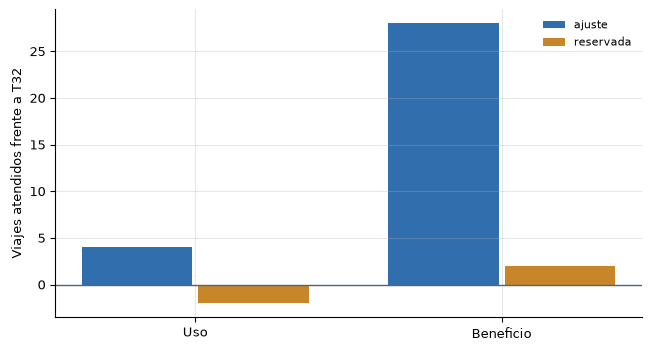

In [2]:
fig, eje = plt.subplots(figsize=(6.4, 3.4), layout="constrained")
otras = t80.loc[t80["estrategia"].ne("actual")]
for i, (periodo, color) in enumerate((("ajuste", "#306eae"), ("reservada", "#c8862a"))):
    g = otras.loc[otras["periodo"].eq(periodo)]
    eje.bar(np.arange(len(g)) + (i - .5) * .38, g["recuperados"], width=.36, color=color, label=periodo)
eje.axhline(0, color="#526576", lw=1)
eje.set(xticks=range(2), xticklabels=["Uso", "Beneficio"], ylabel="Viajes atendidos frente a T32")
eje.legend(frameon=False)
guardar_figura(fig, "movilidad", "T80_anclajes")

## T81 · Despliegue por etapas

Viajes atendidos en la semana reservada con la primera etapa, con las capacidades tras las tres ampliaciones y con el despliegue completo de T32. Las barras de las semanas del ajuste comparan cada etapa con el despliegue completo en esa misma semana.

,etapa,periodo,anclajes,atendidos,sin_anclaje,atendidos_completo,anclajes_completo,solicitudes,saturadas,modulos_nuevos
0,semana 1,ajuste,748,3796,335,4043.0,966.0,5334,77.0,18.0
1,semana 2,ajuste,820,3905,237,4089.0,966.0,5228,68.0,18.0
2,semana 3,ajuste,892,4526,215,4617.0,966.0,6194,66.0,18.0
3,primera etapa,reservada,748,4358,423,NaN,NaN,6614,NaN,NaN
4,tras las ampliaciones,reservada,964,4635,113,NaN,NaN,6614,NaN,NaN
5,despliegue completo,reservada,966,4670,72,NaN,NaN,6614,NaN,NaN


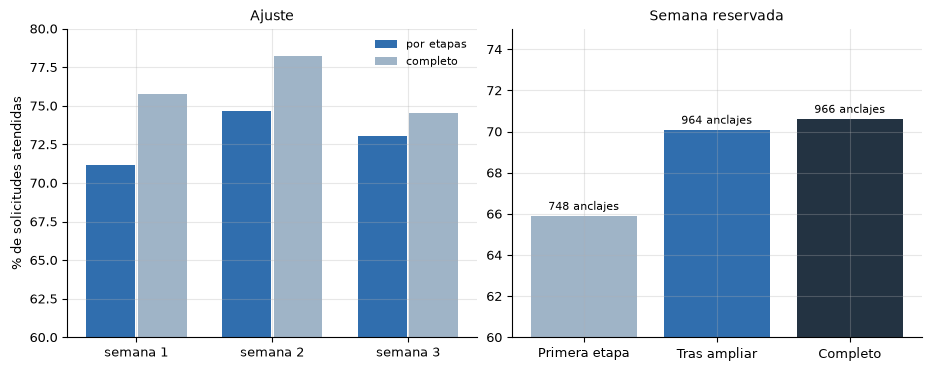

In [3]:
display(t81)
aj = t81.loc[t81["periodo"].eq("ajuste")]
res = t81.loc[t81["periodo"].eq("reservada")].set_index("etapa")
fig, ejes = plt.subplots(1, 2, figsize=(9.2, 3.6), layout="constrained")
x = np.arange(len(aj))
ejes[0].bar(x - .19, aj["atendidos"] / aj["solicitudes"] * 100, width=.36, color="#306eae", label="por etapas")
ejes[0].bar(x + .19, aj["atendidos_completo"] / aj["solicitudes"] * 100, width=.36, color="#9fb4c7", label="completo")
ejes[0].set(xticks=x, xticklabels=aj["etapa"], ylabel="% de solicitudes atendidas", ylim=(60, 80), title="Ajuste")
ejes[0].legend(frameon=False)
ejes[1].bar(range(len(res)), res["atendidos"] / res["solicitudes"] * 100, color=["#9fb4c7", "#306eae", "#233342"])
for i, r in enumerate(res.itertuples()):
    ejes[1].text(i, r.atendidos / r.solicitudes * 100 + .3, f"{r.anclajes} anclajes", ha="center", fontsize=8)
ejes[1].set(xticks=range(len(res)), xticklabels=["Primera etapa", "Tras ampliar", "Completo"], ylim=(60, 75),
            title="Semana reservada")
guardar_figura(fig, "movilidad", "T81_etapas")

In [4]:
aj80 = t80.set_index(["periodo", "estrategia"])
mejor = aj80.loc[("ajuste", "beneficio")]
res80 = aj80.loc[("reservada", "beneficio")]
uso = aj80.loc[("reservada", "uso")]
ref = aj80.loc[("reservada", "actual")]
cambio = estaciones.assign(d=estaciones["final"] - estaciones["completo"])
display(Markdown(f"""## Conclusiones
- **T80.** La asignación de T32 ya está cerca de su óptimo con diez traslados. La búsqueda voraz recupera **{mejor['recuperados']:.0f}** viajes en el ajuste ({mejor['por_anclaje']:.1f} por anclaje), pero solo **{res80['recuperados']:.0f}** en la semana reservada: casi toda la ganancia es ajuste al periodo de elección. Llevar anclajes a las estaciones más usadas da {uso['recuperados']:+.0f} viajes en la reserva. Se mantiene la asignación de T32.
- **T81.** La primera etapa instala **{res.loc['primera etapa', 'anclajes']}** anclajes ({(1 - res.loc['primera etapa', 'anclajes'] / res.loc['despliegue completo', 'anclajes']) * 100:.0f} % menos) y atiende {res.loc['primera etapa', 'atendidos']:.0f} viajes en la reserva, **{res.loc['despliegue completo', 'atendidos'] - res.loc['primera etapa', 'atendidos']:.0f}** menos que el despliegue completo; el motivo son las devoluciones sin hueco ({res.loc['primera etapa', 'sin_anclaje']:.0f} frente a {res.loc['despliegue completo', 'sin_anclaje']:.0f}).
- Tras tres ampliaciones semanales ({t81.attrs['modulos']} módulos de {MODULO}, {res.loc['tras las ampliaciones', 'anclajes']} anclajes) se atienden {res.loc['tras las ampliaciones', 'atendidos']:.0f} viajes, **{res.loc['despliegue completo', 'atendidos'] - res.loc['tras las ampliaciones', 'atendidos']:.0f}** menos que el despliegue completo. Cada módulo recupera {t81.attrs['recuperados_por_modulo']:.1f} viajes en la reserva.
- El despliegue por etapas es viable para repartir la inversión, pero tres semanas de observación no igualan el dimensionado con todo el ajuste: el reparto final se separa del de T32 en {int((cambio['d'] != 0).sum())} estaciones, con diferencias de {cambio['d'].min():+d} a {cambio['d'].max():+d} anclajes.
"""))

## Conclusiones
- **T80.** La asignación de T32 ya está cerca de su óptimo con diez traslados. La búsqueda voraz recupera **28** viajes en el ajuste (2.8 por anclaje), pero solo **2** en la semana reservada: casi toda la ganancia es ajuste al periodo de elección. Llevar anclajes a las estaciones más usadas da -2 viajes en la reserva. Se mantiene la asignación de T32.
- **T81.** La primera etapa instala **748** anclajes (23 % menos) y atiende 4358 viajes en la reserva, **312** menos que el despliegue completo; el motivo son las devoluciones sin hueco (423 frente a 72).
- Tras tres ampliaciones semanales (54 módulos de 4, 964 anclajes) se atienden 4635 viajes, **35** menos que el despliegue completo. Cada módulo recupera 5.1 viajes en la reserva.
- El despliegue por etapas es viable para repartir la inversión, pero tres semanas de observación no igualan el dimensionado con todo el ajuste: el reparto final se separa del de T32 en 120 estaciones, con diferencias de -3 a +5 anclajes.
